# ML architectures: an SVD network and two autoencoder designs

The task: learn a map from a few **parameters** $\theta$ to a **curve** $\phi(t)$ of 1024 values, from examples. Here the curve is a mock
version of the (2,2) phase of an eccentric binary, but the architecture can be applied to different kinds of data. The notebook trains three designs combining SVD compression with autoencoder. The design efficiency can be different depending on the data. some guidelines towards use case are given below. The three designs include:

1. **SVD + network**: an SVD compresses the curves to a short vector of coefficients; a flat network (6 layers of one width,
   LayerNorm + GELU in every layer) maps the parameters to those coefficients.
2. **SVD + autoencoder**: an autoencoder is first trained on the coefficients alone (compress to a small latent vector and
   back), then a parameter network learns to produce that latent vector, and the pretrained decoder turns it into coefficients.
3. **Average**: the mean of two models. **A** is the same autoencoder, but on the data itself, every sample. **B** is the
   direct network of design 1.

The layers, initialisation, optimiser (Adam, learning rate cut by 10 on plateaus, L1 loss) and the two-stage autoencoder training are
those of our full model. Only the sizes and epoch counts are smaller here, so everything runs on a laptop CPU in a few minutes. The full
sizes are in the comments.

### Which design for which data?

All three learn the same thing, parameters $\to$ curve, but they compress the curve differently. Which one is most promising depends
mostly on how well a **linear** basis (the SVD) can describe your curves, and on how much training data you have.

**1. SVD + network: the default; start here.**
- Works best when the curves compress well linearly: the singular values (section 2) fall fast and a modest number of SVD
  coefficients reproduces the curves to well below the accuracy you need. That is typical for smooth curves whose features stay at
  roughly the same place on the grid and change gradually with the parameters.
- One network, one training stage, few choices to tune, and fast to evaluate. Its error is simply the network error plus the SVD
  truncation error, so it is easy to diagnose.

**2. SVD + autoencoder: when many coefficients carry only a few real degrees of freedom.**
- Promising when you need many SVD coefficients (hundreds or more) while the curves depend on only a few parameters: the coefficient
  vectors then lie on a low-dimensional, curved surface, which the autoencoder can learn as a small latent vector. The parameter network
  then only has to predict a few latent numbers instead of every coefficient.
- Stage 1 needs no parameters, only curves. So it can use extra curves whose parameters are unknown or differently defined, and the
  latent space can be reused for other tasks (for example a generative model or parameter estimation).
- Costs: two training stages, and the decoder's own error adds to the parameter network's. In our full model it came close to the
  direct network on average but was worse at the edges of the parameter range, where the latent space is least constrained.

**3A. Autoencoder (no SVD): when the SVD does not compress well.**
- Promising when the SVD floor stays high unless you keep very many coefficients: for example when features **move** along the grid
  as the parameters change (a peak or a feature whose position shifts), which a linear basis can only describe with many components.
  The autoencoder can learn such nonlinear structure directly.
- Costs: the network sees every sample (here 1024, in our full model 10,613), so its first layers are large; it needs more training
  data and more training time, and it has no linear basis to fall back on.

**3. Average: when two models make different errors.**
- Averaging helps when two models are about equally accurate and make **different** errors: the errors then partly cancel, as in any
  ensemble. If one model is clearly better, the average is worse than that model alone. That is what happens in this notebook (and
  in our full model), where the direct network is more accurate than the autoencoder without SVD.

**A quick way to choose.** Look at the SVD floor and the singular values in section 2 first. A low floor with a manageable number of
coefficients points to design 1. A floor that stays high points to design 3A. Many coefficients but only a few parameters, with a
direct network that struggles to reach the floor, points to design 2. With little training data, prefer the simplest model (design 1).

Files: `mock_data.py` (the data), `architectures.py` (the networks), `training.py` (SVD basis and training loops), `figures/` (the three
architecture diagrams).

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
import torch
from IPython.display import Image, display

from mock_data import make_dataset, network_inputs
from architectures import Encoder, FlatDirectNetwork, count_weights
from training import fit_svd_basis, Scaler, Recipe, train_direct, train_two_stage_autoencoder, predict

torch.manual_seed(0)
np.random.seed(0)
print("torch", torch.__version__, "| device:", "cuda" if torch.cuda.is_available() else "cpu")

torch 2.12.0+cu130 | device: cpu


## 1. The data

3000 examples. Each has parameters $\theta = (q, e_0, \zeta_0)$ and a curve $\phi(t)$ of 1024 values on a time grid ending at $t=0$,
denser near the end, where the curve changes fastest. $e_0$ sets the size of small oscillations on top of the smooth rise, $\zeta_0$ where
they start. The networks see 4 inputs: $1/q$, $e_0/0.5$, $\sin\zeta_0$, $\cos\zeta_0$.

The curve is divided by 300 before fitting, so the targets have a size of order one. 80% of the examples are for training, 10% for
validation (learning-rate schedule and best epoch) and 10% for the final test.

The right-hand plot is for display only: it subtracts a smooth polynomial fit from each curve, so the small oscillations that $e_0$ adds
(about $\pm 1$ on a curve of size ~180) become visible. The networks always see the full curve, as in the left-hand plot.

2400 training, 300 validation, 300 test examples; 4 inputs, 1024 values per curve


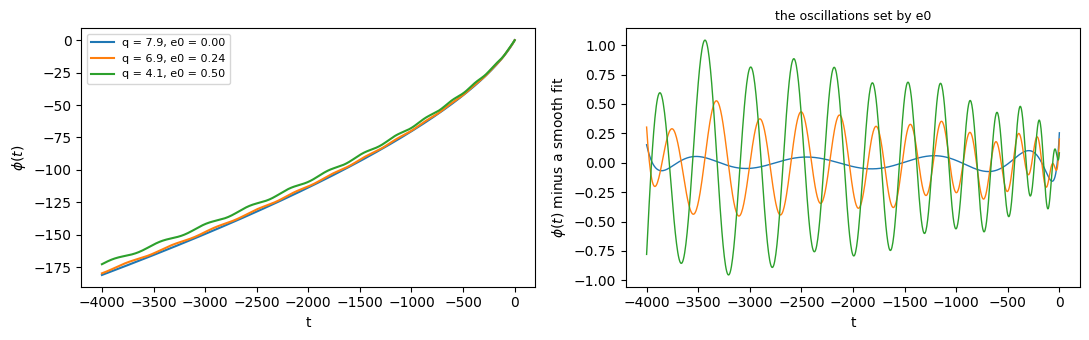

In [2]:
N_SAMPLES, N_TIMES = 3000, 1024       # full model: ~900,000 examples, 10,613 samples per curve
NORM = 300.0

theta, t, phase = make_dataset(N_SAMPLES, N_TIMES, seed=0)
phase = phase / NORM
x = network_inputs(theta)             # (n, 4)

idx = np.random.default_rng(1).permutation(N_SAMPLES)
tr, va, te = idx[: int(.8 * N_SAMPLES)], idx[int(.8 * N_SAMPLES): int(.9 * N_SAMPLES)], idx[int(.9 * N_SAMPLES):]
print(f"{len(tr)} training, {len(va)} validation, {len(te)} test examples; {x.shape[1]} inputs, {N_TIMES} values per curve")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
for i in np.argsort(theta[:, 1])[[0, len(theta) // 2, -1]]:
    lab = f"q = {theta[i, 0]:.1f}, e0 = {theta[i, 1]:.2f}"
    ax[0].plot(t, phase[i] * NORM, label=lab)
    smooth = np.polyval(np.polyfit(t, phase[i] * NORM, 9), t)
    ax[1].plot(t, phase[i] * NORM - smooth, lw=1, label=lab)
ax[0].set_ylabel(r"$\phi(t)$"); ax[0].set_xlabel("t"); ax[0].legend(fontsize=8)
ax[1].set_ylabel(r"$\phi(t)$ minus a smooth fit"); ax[1].set_xlabel("t"); ax[1].set_title("the oscillations set by e0", fontsize=9)
plt.tight_layout(); plt.show()

## 2. SVD compression

A truncated SVD of the training curves gives a basis of 64 curves; every example becomes 64 coefficients. The basis is fitted on the
training curves only. How well the basis alone reproduces the test curves is the floor no network can beat.

For these mock curves the floor is at machine precision: they form such a simple family that 64 basis curves reproduce them exactly, so
every error further on comes from the networks. On real data the floor is much higher, because the basis never captures everything.

test curves reproduced by the basis alone: rms residual median 1.4e-14 (the floor)


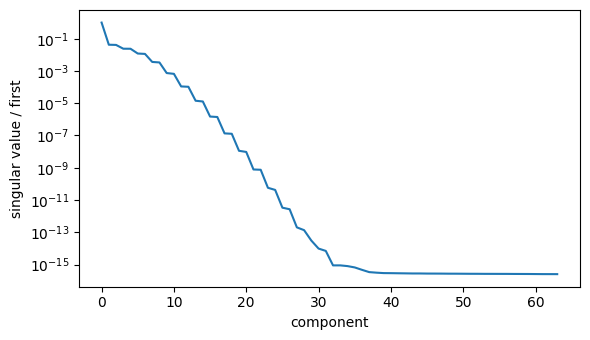

In [3]:
N_COEF = 64                           # full model: 1024

basis = fit_svd_basis(phase[tr], N_COEF)
coef = basis.transform(phase)

floor = np.sqrt(np.mean((basis.inverse_transform(coef[te]) - phase[te]) ** 2, axis=1)) * NORM
print(f"test curves reproduced by the basis alone: rms residual median {np.median(floor):.1e} (the floor)")

plt.figure(figsize=(6, 3.5))
plt.semilogy(basis.singular_values / basis.singular_values[0])
plt.xlabel("component"); plt.ylabel("singular value / first"); plt.tight_layout(); plt.show()

# the networks learn the coefficients divided by one common scale (keeps their relative sizes)
scaler = Scaler.fit(coef[tr])
y = scaler(coef)


def curve_from_coefficients(c_scaled):
    return basis.inverse_transform(scaler.inverse(c_scaled))

## 3. Training settings

All networks use the same recipe; only the network differs. Our full runs use up to 5000 epochs with patience 125 and stop early once the
learning rate reaches its floor; here 400 epochs and patience 40, so the notebook finishes in minutes. Raise `EPOCHS` (and `PATIENCE`)
to train to convergence.

In [4]:
EPOCHS, PATIENCE = 400, 40            # full model: up to 5000 epochs, patience 125
recipe = Recipe(epochs=EPOCHS, patience=PATIENCE, print_every=100)
results = {}                          # predicted test curves, per design
cost = {}                             # training time, weights and epochs, per design

## 4. Design 1: SVD + network

Parameters $\to$ SVD coefficients through 6 hidden layers of one width, each Linear $\to$ LayerNorm $\to$ GELU, then a linear output
layer. This model does **not** include an autoencoder.

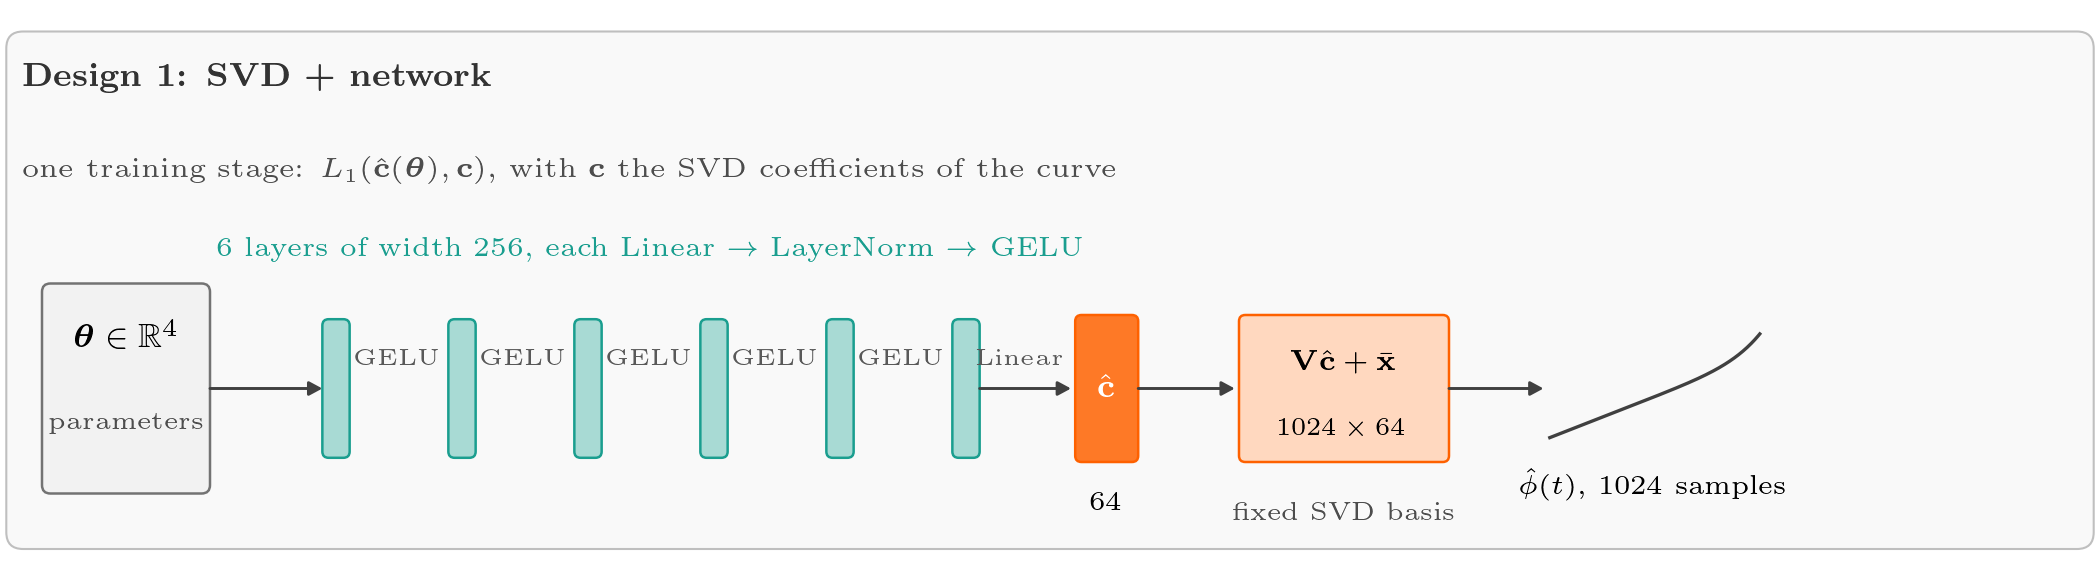

In [5]:
display(Image("figures/design1_svd_network.png", width=900))

In [6]:
t0 = time.time()
torch.manual_seed(0)
net1 = FlatDirectNetwork(x.shape[1], N_COEF, width=256, n_layers=6)   # full model: width 1024
print(f"{count_weights(net1):,} weights")
net1, hist1 = train_direct(net1, x[tr], y[tr], x[va], y[va], recipe, name="design 1")
results["1. SVD + network"] = curve_from_coefficients(predict(net1, x[te]))
cost["1. SVD + network"] = dict(seconds=time.time() - t0, weights=count_weights(net1), epochs=len(hist1["val"]))
print(f"design 1 done in {cost['1. SVD + network']['seconds']:.0f} s")

349,760 weights


[design 1] epoch   100 | train 8.807e-03 | val 1.083e-02 | lr 1e-03 | 3 s


[design 1] epoch   200 | train 8.780e-03 | val 9.468e-03 | lr 1e-03 | 5 s


[design 1] epoch   300 | train 6.367e-03 | val 5.759e-03 | lr 1e-03 | 8 s


[design 1] epoch   400 | train 6.073e-04 | val 6.162e-04 | lr 1e-04 | 11 s
[design 1] best validation loss 5.582e-04
design 1 done in 11 s


## 5. Design 2: SVD + autoencoder

**Stage 1.** The autoencoder learns to squeeze the 64 coefficients into a latent vector $\mathbf z$ of 16 numbers and back
(coefficients $\to 8h \to 4h \to 2h \to h \to L \to h \to 2h \to 4h \to 8h \to$ coefficients). No parameters are involved yet.

**Stage 2.** The encoder is dropped. A parameter network (inputs $\to h \to 4h \to 4h \to h \to L$) learns to produce the latent vector
from the parameters, and the pretrained decoder (which keeps training) turns it into coefficients.

The bar heights in the diagram grow with the logarithm of the layer width; the dark bars are the latent vector.

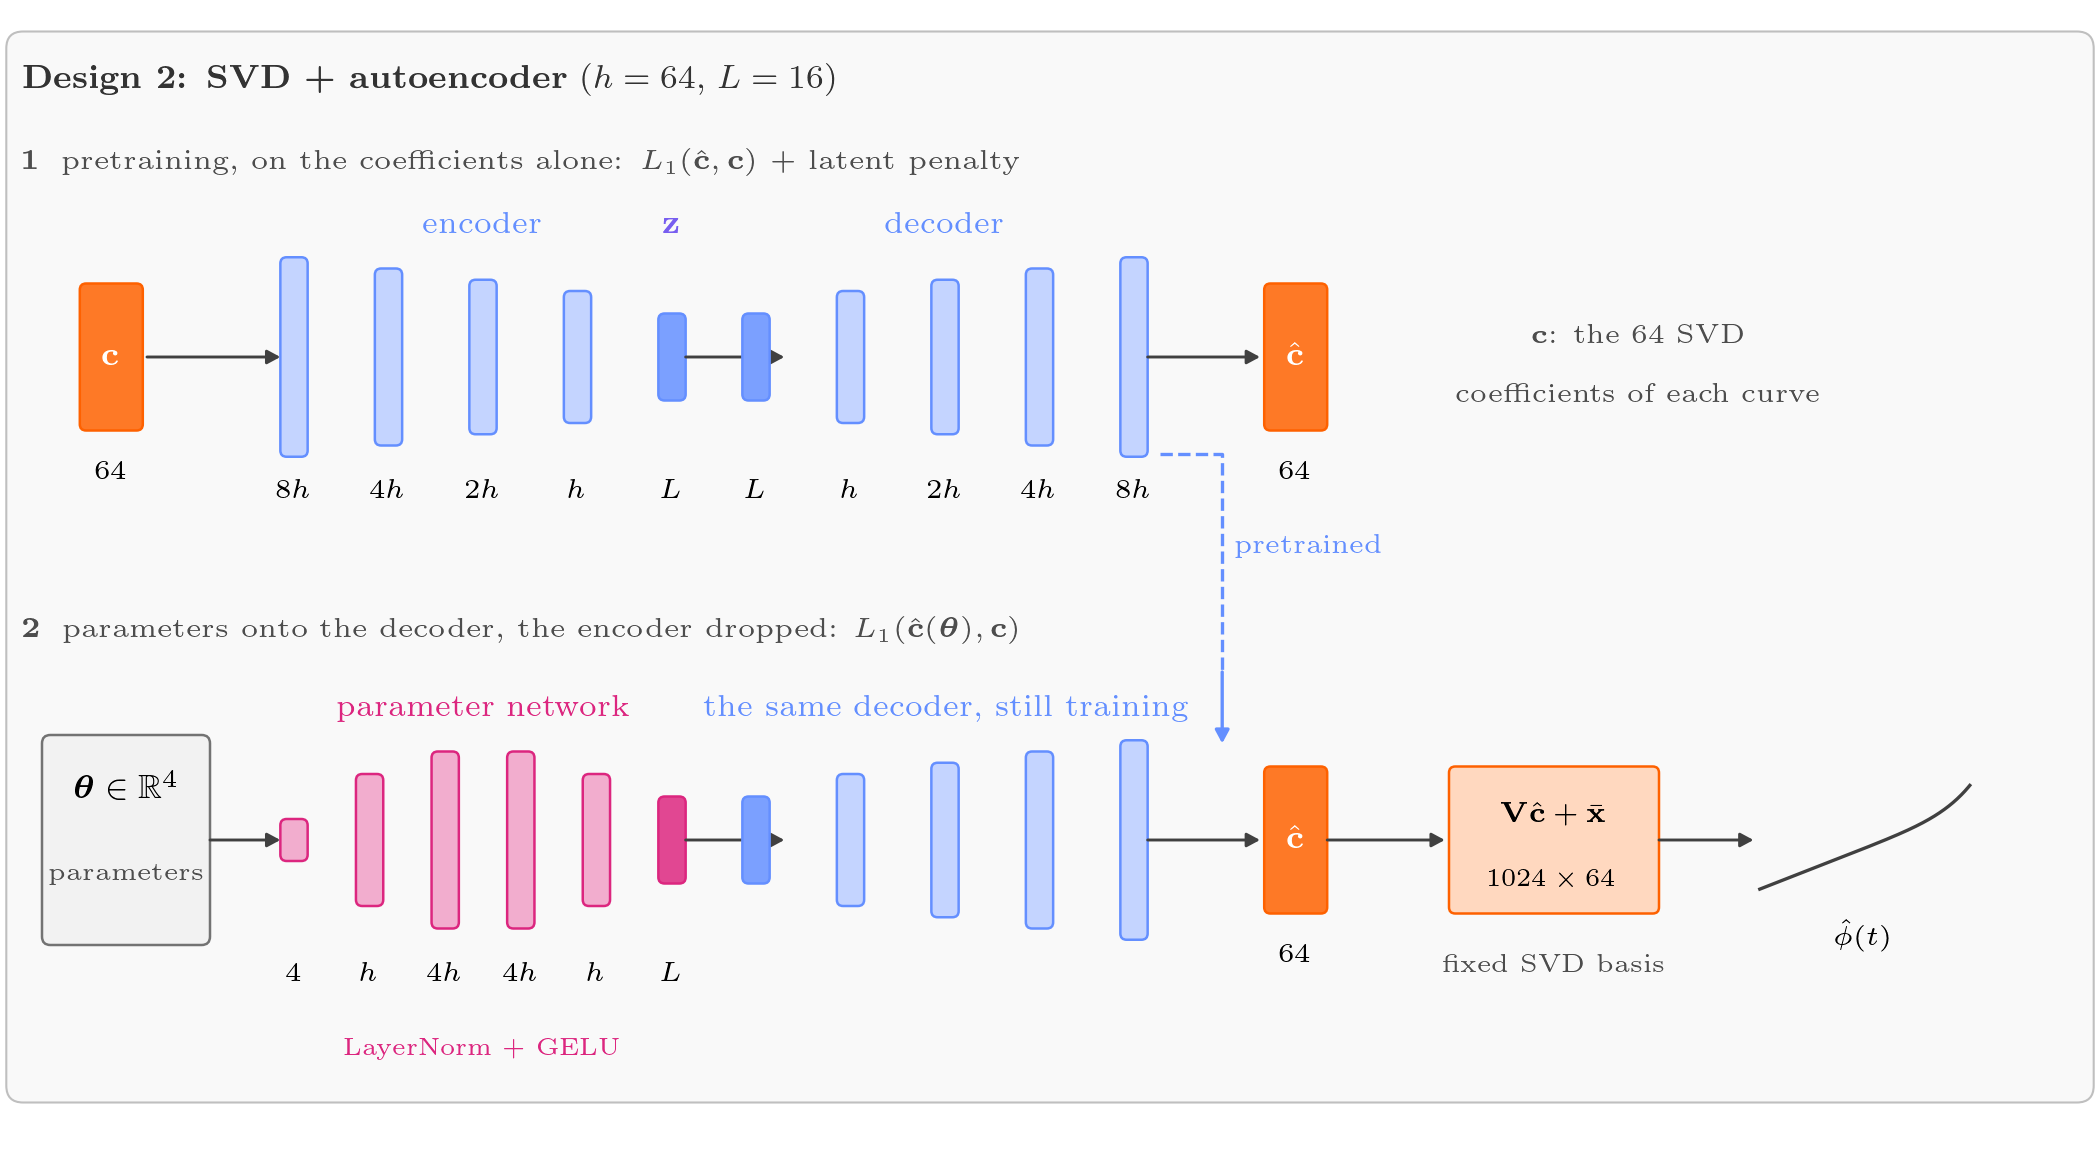

In [7]:
display(Image("figures/design2_svd_autoencoder.png", width=900))

In [8]:
t0 = time.time()
LATENT, HIDDEN = 16, 64               # full model: L = 32, h = 256
model2, hist2 = train_two_stage_autoencoder(x[tr], y[tr], x[va], y[va], latent=LATENT, hidden=HIDDEN, regulariser=1e-3,
                                            pretrain=recipe, second=recipe, name="design 2")
print(f"{count_weights(model2):,} weights in the parameters -> coefficients model")
results["2. SVD + autoencoder"] = curve_from_coefficients(predict(model2, x[te]))
# weights trained: the encoder (stage 1 only), the decoder and the parameter network
cost["2. SVD + autoencoder"] = dict(seconds=time.time() - t0, weights=count_weights(Encoder(N_COEF, LATENT, HIDDEN)) + count_weights(model2),
                                                  epochs=len(hist2["pretrain"]["val"]) + len(hist2["regression"]["val"]))
print(f"design 2 done in {cost['2. SVD + autoencoder']['seconds']:.0f} s")

[design 2 pretrain] epoch   100 | val reconstruction + penalty 1.198e-02 | lr 1e-03 | 3 s


[design 2 pretrain] epoch   200 | val reconstruction + penalty 1.056e-02 | lr 1e-03 | 6 s


[design 2 pretrain] epoch   300 | val reconstruction + penalty 1.964e-03 | lr 1e-04 | 9 s


[design 2 pretrain] epoch   400 | val reconstruction + penalty 1.767e-03 | lr 1e-04 | 12 s


[design 2 parameters] epoch   100 | train 9.083e-03 | val 8.023e-03 | lr 1e-03 | 3 s


[design 2 parameters] epoch   200 | train 1.602e-03 | val 1.767e-03 | lr 1e-04 | 5 s


[design 2 parameters] epoch   300 | train 1.425e-03 | val 1.570e-03 | lr 1e-04 | 8 s


[design 2 parameters] epoch   400 | train 1.245e-03 | val 1.603e-03 | lr 1e-04 | 11 s
[design 2 parameters] best validation loss 1.267e-03
308,368 weights in the parameters -> coefficients model
design 2 done in 23 s


## 6. Design 3: average of two models

**A** is the same two-stage autoencoder, now on the **curve itself** (all 1024 samples, each standardised over the training set) instead
of on the coefficients. **B** is the direct network of design 1, the same trained network, so it is not trained again. The prediction is
the mean of the two predicted curves.

In the diagram, part B is only a reference to design 1, whose network is drawn in section 4.

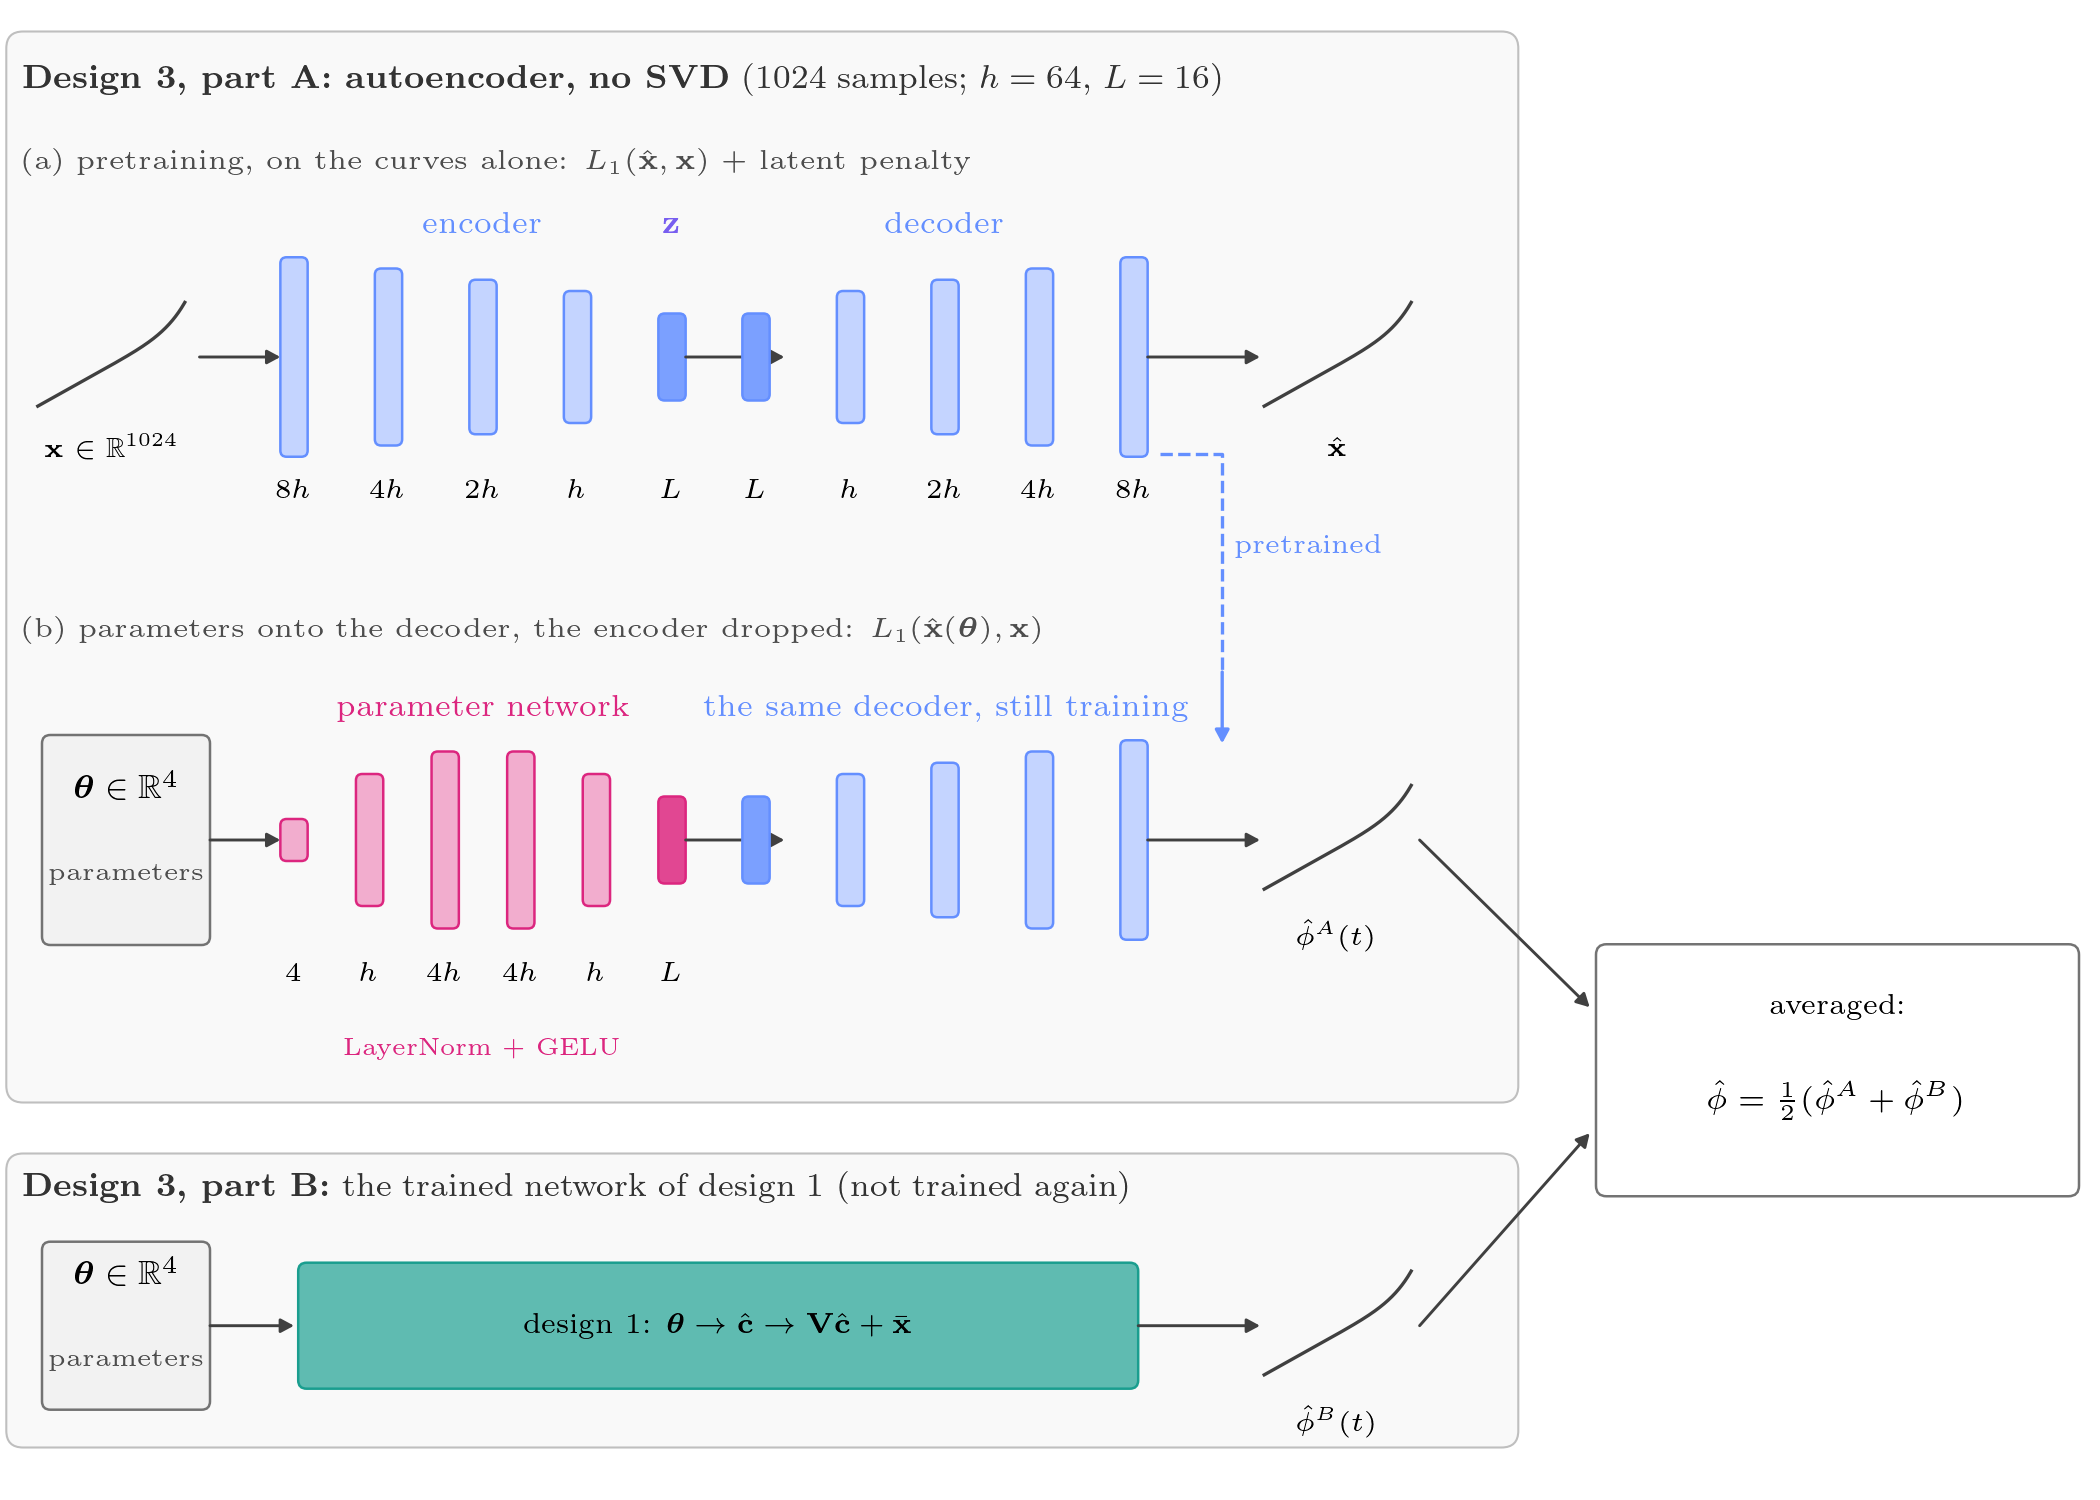

In [9]:
display(Image("figures/design3_average.png", width=900))

In [10]:
t0 = time.time()
# A: autoencoder on the standardised curve samples
mu_t, sd_t = phase[tr].mean(axis=0), phase[tr].std(axis=0) + 1e-12
ys = ((phase - mu_t) / sd_t).astype(np.float32)
model_A, hist_A = train_two_stage_autoencoder(x[tr], ys[tr], x[va], ys[va], latent=LATENT, hidden=HIDDEN, regulariser=1e-3,
                                              pretrain=recipe, second=recipe, name="design 3A")
curve_A = predict(model_A, x[te]) * sd_t + mu_t

# B: the direct network of design 1 (already trained)
curve_B = results["1. SVD + network"]

results["3A. Autoencoder"] = curve_A
results["3. Average"] = 0.5 * (curve_A + curve_B)
cA = dict(seconds=time.time() - t0, weights=count_weights(Encoder(N_TIMES, LATENT, HIDDEN)) + count_weights(model_A),
          epochs=len(hist_A["pretrain"]["val"]) + len(hist_A["regression"]["val"]))
c1 = cost["1. SVD + network"]
cost["3A. Autoencoder"] = cA
cost["3. Average"] = {k: cA[k] + c1[k] for k in cA}   # A plus the design-1 network it reuses
print(f"design 3A done in {cA['seconds']:.0f} s")

[design 3A pretrain] epoch   100 | val reconstruction + penalty 1.569e-02 | lr 1e-04 | 7 s


[design 3A pretrain] epoch   200 | val reconstruction + penalty 9.369e-03 | lr 1e-04 | 14 s


[design 3A pretrain] epoch   300 | val reconstruction + penalty 9.389e-03 | lr 1e-04 | 21 s


[design 3A pretrain] epoch   400 | val reconstruction + penalty 6.163e-03 | lr 1e-05 | 27 s


[design 3A parameters] epoch   100 | train 5.084e-02 | val 4.242e-02 | lr 1e-03 | 5 s


[design 3A parameters] epoch   200 | train 6.158e-03 | val 6.816e-03 | lr 1e-04 | 10 s


[design 3A parameters] epoch   300 | train 5.271e-03 | val 5.595e-03 | lr 1e-04 | 15 s


[design 3A parameters] epoch   400 | train 4.796e-03 | val 4.702e-03 | lr 1e-04 | 20 s
[design 3A parameters] best validation loss 4.702e-03
design 3A done in 47 s


## 7. Comparison on the test examples

For each test example: the rms difference between the predicted and the true curve (after undoing the factor 300). Lower is better.
"Floor" is what the SVD basis alone allows. The second table shows what each design costs to train: the weights it has to learn
(for the autoencoders including the encoder, which is used only in stage 1), the epochs run, and the training time on this machine.

Why the costs differ:
- **Design 1** trains one network once.
- **Design 2** trains two networks one after the other (the autoencoder, then the parameter network onto the decoder), so roughly twice
  the epochs; its networks are about as large as design 1's, because they work on the same 64 coefficients.
- **Design 3A** also trains in two stages, but its encoder and decoder see the whole curve: the first encoder layer and the last decoder
  layer have $1024 \times 8h$ weights each. That part grows with the length of the curve: in our full model (10,613 samples, $h = 256$)
  the autoencoder without SVD has about 26 million weights, against about 5.5 million for our direct network.
- **Design 3** costs design 3A plus design 1, since it needs both.

The times are for a short run (400 epochs per stage at most) on whatever this notebook runs on, so treat the ratios, not the seconds,
as the result. With full training (up to 5000 epochs per stage) all times grow, the ratios roughly stay.

design                                         median        99%   [rms error per curve]
floor (SVD basis alone)                      1.40e-14   2.46e-14
1. SVD + network                             4.70e-03   1.95e-02
2. SVD + autoencoder                         1.15e-02   3.73e-02
3A. Autoencoder                              1.98e-02   5.24e-02
3. Average                                   1.07e-02   3.77e-02

design                                        weights  epochs  train time  x design 1
1. SVD + network                              349,760     400        11 s        1.0x
2. SVD + autoencoder                          515,168     800        23 s        2.0x
3A. Autoencoder                             1,499,168     800        47 s        4.1x
3. Average                                  1,848,928    1200        58 s        5.1x


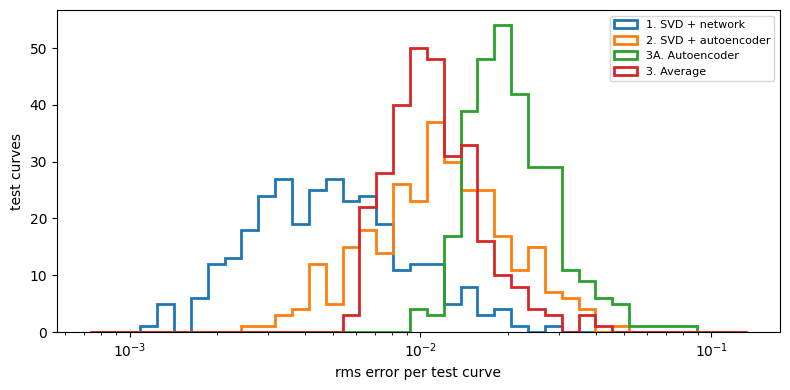

In [11]:
true = phase[te]
print(f"{'design':42s} {'median':>10s} {'99%':>10s}   [rms error per curve]")
print(f"{'floor (SVD basis alone)':42s} {np.median(floor):10.2e} {np.percentile(floor, 99):10.2e}")
rms = {}
for name, pred in results.items():
    rms[name] = np.sqrt(np.mean((pred - true) ** 2, axis=1)) * NORM
    print(f"{name:42s} {np.median(rms[name]):10.2e} {np.percentile(rms[name], 99):10.2e}")

ref = cost["1. SVD + network"]["seconds"]
print(f"\n{'design':42s} {'weights':>10s} {'epochs':>7s} {'train time':>11s} {'x design 1':>11s}")
for name, c in cost.items():
    print(f"{name:42s} {c['weights']:10,d} {c['epochs']:7d} {c['seconds']:9.0f} s {c['seconds'] / ref:10.1f}x")

bins = np.logspace(np.log10(min(v.min() for v in rms.values())) - .2, np.log10(max(v.max() for v in rms.values())) + .2, 40)
plt.figure(figsize=(8, 4))
for name, v in rms.items():
    plt.hist(v, bins, histtype="step", lw=2, label=name)
plt.xscale("log"); plt.xlabel("rms error per test curve"); plt.ylabel("test curves"); plt.legend(fontsize=8)
plt.tight_layout(); plt.show()

## 8. One test example

The true and predicted curve for the median test example of design 1, and the error of every design along the curve.

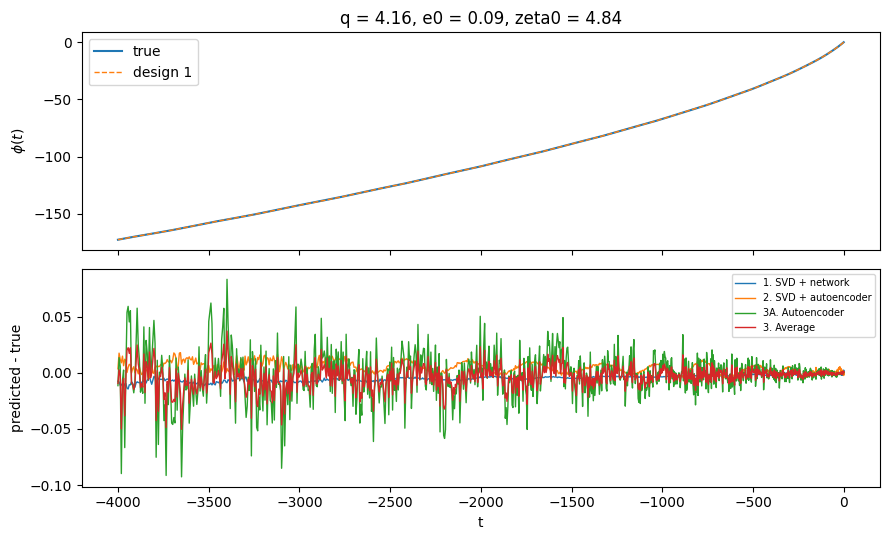

In [12]:
i = int(np.argsort(rms["1. SVD + network"])[len(te) // 2])
q, e0, z0 = theta[te][i]
fig, ax = plt.subplots(2, 1, figsize=(9, 5.5), sharex=True)
ax[0].plot(t, true[i] * NORM, lw=1.5, label="true")
ax[0].plot(t, results["1. SVD + network"][i] * NORM, lw=1, ls="--", label="design 1")
ax[0].set_ylabel(r"$\phi(t)$"); ax[0].legend(); ax[0].set_title(f"q = {q:.2f}, e0 = {e0:.2f}, zeta0 = {z0:.2f}")
for name, pred in results.items():
    ax[1].plot(t, (pred[i] - true[i]) * NORM, lw=1, label=name)
ax[1].set_ylabel("predicted - true"); ax[1].set_xlabel("t"); ax[1].legend(fontsize=7)
plt.tight_layout(); plt.show()

## Notes

* **This is a demonstration, not a benchmark.** Which design wins depends on the data. On our real data the autoencoder on the
  coefficients (design 2) came close to a direct network on average but was worse at the edges of the parameter range, and the
  average of two models (design 3) was about twice as far off.
* With the short default training the numbers above also depend on when each network's first learning-rate cut happens; raise `EPOCHS`
  before comparing designs. One seed and 300 test examples also leave a few-percent scatter.
* The validation set sets the learning-rate cuts and picks the best epoch; the test set is used only for the comparison.